# ONI contínuo — comparação controlada na validação

Esta rodada compara ausência de ENSO, indicadores binários e ONI contínuo. A nova
versão acrescenta a intensidade e o sinal do ONI aos mesmos atributos de base.

Mantemos: alvo de aumento de 50% em quatro semanas, janela de 12 semanas, atraso
ONI de quatro semanas, mesmas datas e rótulos, sementes 42/123/2025/7/99, limiar 0,5.
RNN/LSTM selecionam a menor perda BCE de validação; RF mantém o maior F1.

Os experimentos anteriores são preservados. Somente treino e validação são
preparados nesta pasta; não há avaliação ou seleção pelo teste nesta rodada.


In [1]:
%matplotlib inline
from pathlib import Path
import runpy
from IPython.display import display

current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'experimento_ONI_continuo' else current
EXPERIMENT_DIR = PROJECT_ROOT / 'experimento_ONI_continuo'
api = runpy.run_path(str(PROJECT_ROOT / 'models/comparar_representacoes_enso.py'))


## 1. Dados, tratamento e janelas

Reconstruímos as entradas a partir da planilha original e mantemos os rótulos e
as datas já congelados no experimento sem ONI. A origem é limitada ao fim da
validação. O scaler é ajustado nas janelas do treino; nenhum atributo é escolhido
pela validação. ONI entra como valor contínuo, com atraso de quatro semanas.


In [2]:
partition_summary = api['prepare_continuous'](PROJECT_ROOT)
display(partition_summary)
import pandas as pd
display(pd.read_csv(EXPERIMENT_DIR / 'results/data/atributos_disponiveis.csv').dropna().head())


,amostras,positivos,prevalencia,primeira_emissao,ultima_emissao,primeiro_alvo,ultimo_alvo
split,,,,,,,
treino,451,127,0.281596,2011-04-10,2019-11-24,2011-05-08,2019-12-22
validacao,153,38,0.248366,2019-12-29,2022-11-27,2020-01-26,2022-12-25


,sample_id,casos_dengue,temperatura_media,umidade_media,chuva_total,semana_sin,semana_cos,ONI
4,4,782.0,26.68,82.34,16.3,0.354605,0.935016,-1.571
5,5,833.0,28.65,70.24,6.7,0.464723,0.885456,-1.400
6,6,1234.0,26.91,75.90,30.3,0.568065,0.822984,-1.400
7,7,1530.0,27.28,74.04,39.3,0.663123,0.748511,-1.400
8,8,1496.0,25.65,81.45,59.9,0.748511,0.663123,-1.400


## 2. Random Forest, RNN e LSTM — cinco sementes

O código comum é o mesmo das rodadas anteriores. RF: 25/50/100/200 árvores,
profundidade 6 e folha mínima 2. Redes: uma camada, 24 unidades, Adam 0,003,
até 150 épocas e paciência 20 pela perda BCE de validação.

A continuação da LSTM de semente 42 até 150 épocas permanece apenas diagnóstica;
não substitui seu checkpoint selecionado. A referência simples de tendência
recente é idêntica à das outras representações.


experimento_ONI_continuo random_forest 42 F1 validação = 0.2553


experimento_ONI_continuo random_forest 123 F1 validação = 0.2553


experimento_ONI_continuo random_forest 2025 F1 validação = 0.3265


experimento_ONI_continuo random_forest 7 F1 validação = 0.2553


experimento_ONI_continuo random_forest 99 F1 validação = 0.2553


experimento_ONI_continuo rnn 42 F1 validação = 0.2917


... (5 outputs left out)

experimento_ONI_continuo lstm 123 F1 validação = 0.2727


experimento_ONI_continuo lstm 2025 F1 validação = 0.2727


experimento_ONI_continuo lstm 7 F1 validação = 0.2667


experimento_ONI_continuo lstm 99 F1 validação = 0.2727


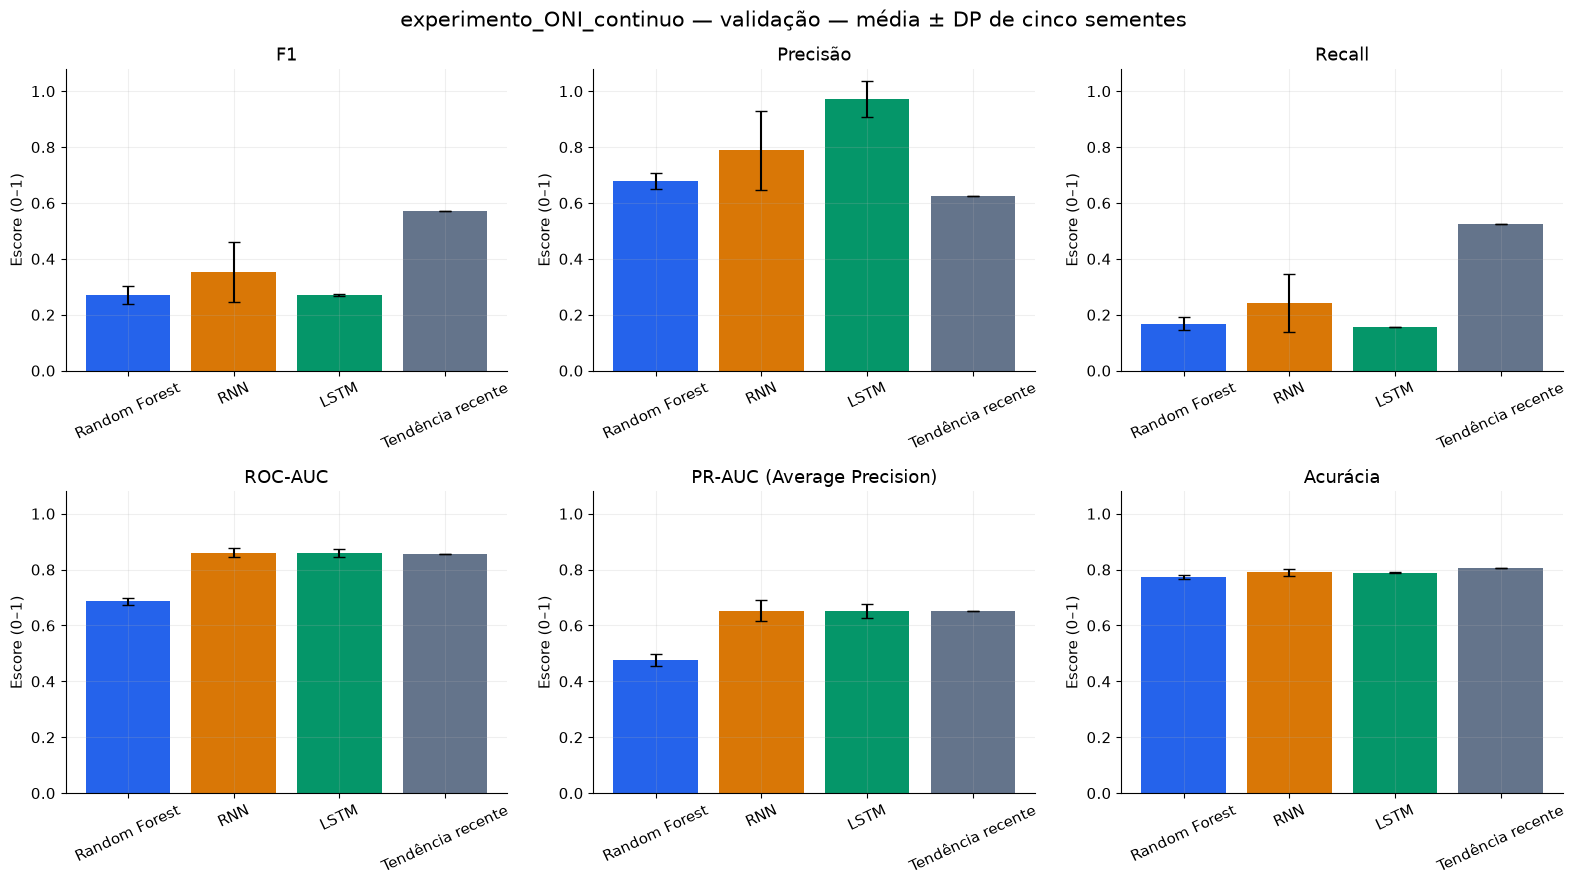

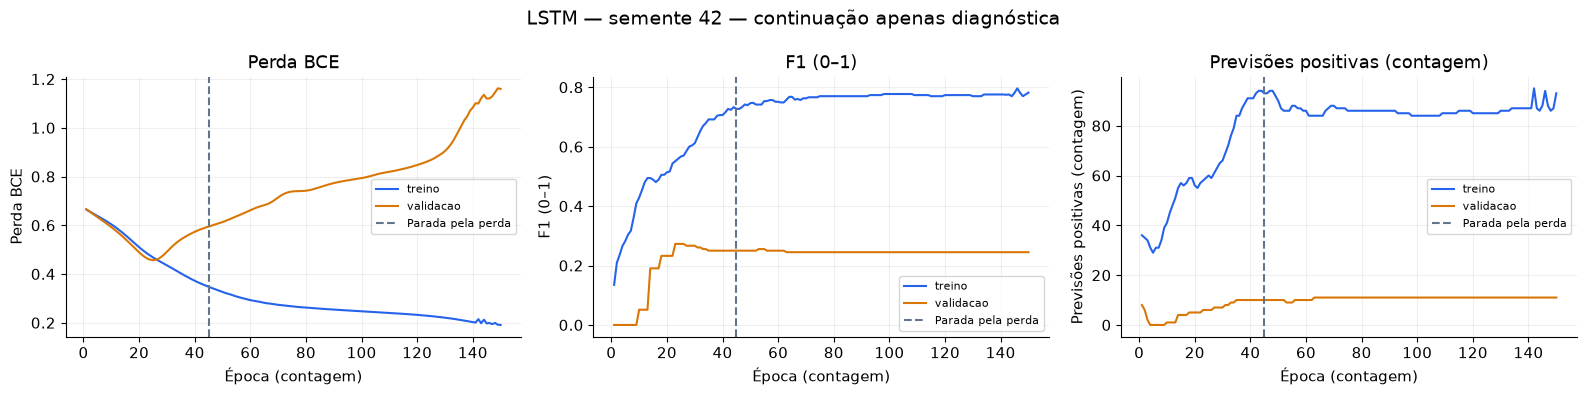

,model,metric,n_runs,mean,std,min,max
0,random_forest,f1,5,0.2696,0.0318,0.2553,0.3265
1,random_forest,precision,5,0.6788,0.0271,0.6667,0.7273
2,random_forest,recall,5,0.1684,0.0235,0.1579,0.2105
3,random_forest,roc_auc,5,0.6870,0.0130,0.6739,0.7077
4,random_forest,pr_auc,5,0.4775,0.0217,0.4649,0.5162
5,random_forest,accuracy,5,0.7739,0.0058,0.7712,0.7843
6,rnn,f1,5,0.3541,0.1070,0.2667,0.4912
7,rnn,precision,5,0.7888,0.1406,0.6500,1.0000
8,rnn,recall,5,0.2421,0.1043,0.1579,0.3684
9,rnn,roc_auc,5,0.8608,0.0161,0.8359,0.8739


In [3]:
stability = api['stability_api']()
validation_summary = stability.run_experiment(EXPERIMENT_DIR, network_selection='loss')
display(validation_summary.round(4))


## 3. Comparação das três representações

Média e DP de F1, precisão, recall, ROC-AUC, PR-AUC (Average Precision) e acurácia.
Também são exportadas diferenças por semente e comparações com a referência simples.
Não selecionamos uma semente vencedora. Esta é uma comparação exploratória no
mesmo período de validação, que já orientou ajustes anteriores; não é confirmação
em dados independentes e não estabelece causalidade.


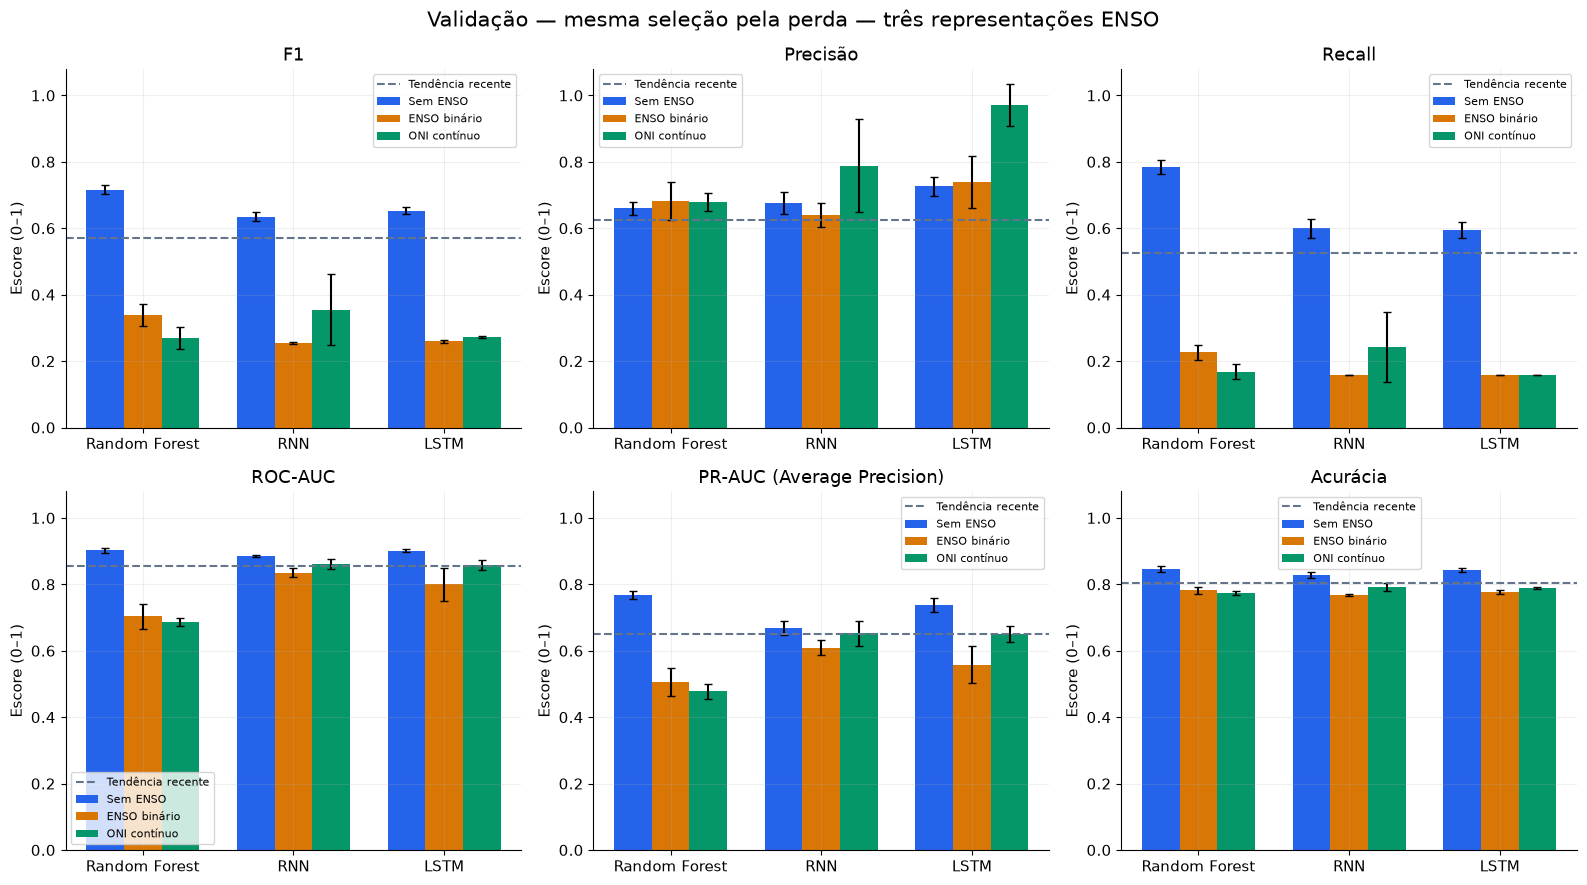

,representation,model,metric,n_runs,mean,std,min,max
0,sem_ENSO,random_forest,f1,5,0.7164,0.0144,0.6988,0.7317
1,sem_ENSO,random_forest,precision,5,0.6597,0.0187,0.6383,0.6818
2,sem_ENSO,random_forest,recall,5,0.7842,0.0220,0.7632,0.8158
3,sem_ENSO,random_forest,roc_auc,5,0.9022,0.0080,0.8888,0.9078
4,sem_ENSO,random_forest,pr_auc,5,0.7680,0.0114,0.7545,0.7834
...,...,...,...,...,...,...,...,...
67,ONI_continuo,tendencia_recente,precision,1,0.6250,0.0000,0.6250,0.6250
68,ONI_continuo,tendencia_recente,recall,1,0.5263,0.0000,0.5263,0.5263
69,ONI_continuo,tendencia_recente,roc_auc,1,0.8558,0.0000,0.8558,0.8558
70,ONI_continuo,tendencia_recente,pr_auc,1,0.6513,0.0000,0.6513,0.6513


,representation,model,metric,n_runs,mean,std,min,max
0,sem_ENSO,random_forest,f1,5,0.7164,0.0144,0.6988,0.7317
6,sem_ENSO,rnn,f1,5,0.6350,0.0141,0.6216,0.6575
12,sem_ENSO,lstm,f1,5,0.6531,0.0111,0.6377,0.6667
18,sem_ENSO,tendencia_recente,f1,1,0.5714,0.0000,0.5714,0.5714
24,ENSO_binario,random_forest,f1,5,0.3398,0.0331,0.3137,0.3922
30,ENSO_binario,rnn,f1,5,0.2532,0.0029,0.2500,0.2553
36,ENSO_binario,lstm,f1,5,0.2598,0.0047,0.2553,0.2667
42,ENSO_binario,tendencia_recente,f1,1,0.5714,0.0000,0.5714,0.5714
48,ONI_continuo,random_forest,f1,5,0.2696,0.0318,0.2553,0.3265
54,ONI_continuo,rnn,f1,5,0.3541,0.1070,0.2667,0.4912


Resultados: /media/lorenzo/SSD/Projetos/ML-Dengue/experimento_ONI_continuo/results/estabilidade_perda
JSON consolidado: /media/lorenzo/SSD/Projetos/ML-Dengue/experimento_ONI_continuo/results/app_resultados.json


In [4]:
comparison = api['compare_representations'](PROJECT_ROOT)
display(comparison.round(4))
display(comparison.query("metric == 'f1'").round(4))
print('Resultados:', EXPERIMENT_DIR / 'results/estabilidade_perda')
print('JSON consolidado:', EXPERIMENT_DIR / 'results/app_resultados.json')
